In [4]:
# !pip install pandas numpy matplotlib seaborn scikit-learn xgboost joblib
import zipfile
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, 
    roc_auc_score, roc_curve
)
import joblib

%matplotlib inline
sns.set_style('whitegrid')
print("import all libraies have successfully !")

import all libraies have successfully !


In [5]:
# Dataset load karna (CSV ya ZIP support both)
if os.path.exists('Loan_Default.csv'):
    df = pd.read_csv('Loan_Default.csv')
elif os.path.exists('archive.zip'):
    with zipfile.ZipFile('archive.zip', 'r') as z:
        df = pd.read_csv(z.open('Loan_Default.csv'))
elif os.path.exists('data/Loan_Default.csv'):
    df = pd.read_csv('data/Loan_Default.csv')
else:
    raise FileNotFoundError("Kripya 'Loan_Default.csv' ya 'archive.zip' ko notebook wale folder mein rakhein!")

print(f"Dataset Shape (Rows, Columns): {df.shape}")
print("\n--- Pehle 5 Rows ---")
display(df.head())

print("\n--- Dataset Info & Data Types ---")
df.info()

Dataset Shape (Rows, Columns): (148670, 34)

--- Pehle 5 Rows ---


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0



--- Dataset Info & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  str    
 3   Gender                     148670 non-null  str    
 4   approv_in_adv              147762 non-null  str    
 5   loan_type                  148670 non-null  str    
 6   loan_purpose               148536 non-null  str    
 7   Credit_Worthiness          148670 non-null  str    
 8   open_credit                148670 non-null  str    
 9   business_or_commercial     148670 non-null  str    
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfro

In [6]:
# Missing values check karna
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_data, 
    'Percentage (%)': missing_percent
})
print("--- Columns jinme Missing Values hain ---")
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False))

print("\n--- Numeric Columns ki Statistical Summary ---")
display(df.describe().T)

--- Columns jinme Missing Values hain ---


,Missing Count,Percentage (%)
Upfront_charges,39642,26.664425
Interest_rate_spread,36639,24.644515
rate_of_interest,36439,24.509989
dtir1,24121,16.224524
property_value,15098,10.155378
LTV,15098,10.155378
income,9150,6.154571
loan_limit,3344,2.249277
approv_in_adv,908,0.610749
submission_of_application,200,0.134526



--- Numeric Columns ki Statistical Summary ---


,count,mean,std,min,25%,50%,75%,max
ID,148670.0,99224.500000,42917.476598,24890.000000,62057.25000,99224.50000,136391.750000,1.735590e+05
year,148670.0,2019.000000,0.000000,2019.000000,2019.00000,2019.00000,2019.000000,2.019000e+03
loan_amount,148670.0,331117.743997,183909.310127,16500.000000,196500.00000,296500.00000,436500.000000,3.576500e+06
rate_of_interest,112231.0,4.045476,0.561391,0.000000,3.62500,3.99000,4.375000,8.000000e+00
Interest_rate_spread,112031.0,0.441656,0.513043,-3.638000,0.07600,0.39040,0.775400,3.357000e+00
Upfront_charges,109028.0,3224.996127,3251.121510,0.000000,581.49000,2596.45000,4812.500000,6.000000e+04
term,148629.0,335.136582,58.409084,96.000000,360.00000,360.00000,360.000000,3.600000e+02
property_value,133572.0,497893.465696,359935.315562,8000.000000,268000.00000,418000.00000,628000.000000,1.650800e+07
income,139520.0,6957.338876,6496.586382,0.000000,3720.00000,5760.00000,8520.000000,5.785800e+05
Credit_Score,148670.0,699.789103,115.875857,500.000000,599.00000,699.00000,800.000000,9.000000e+02


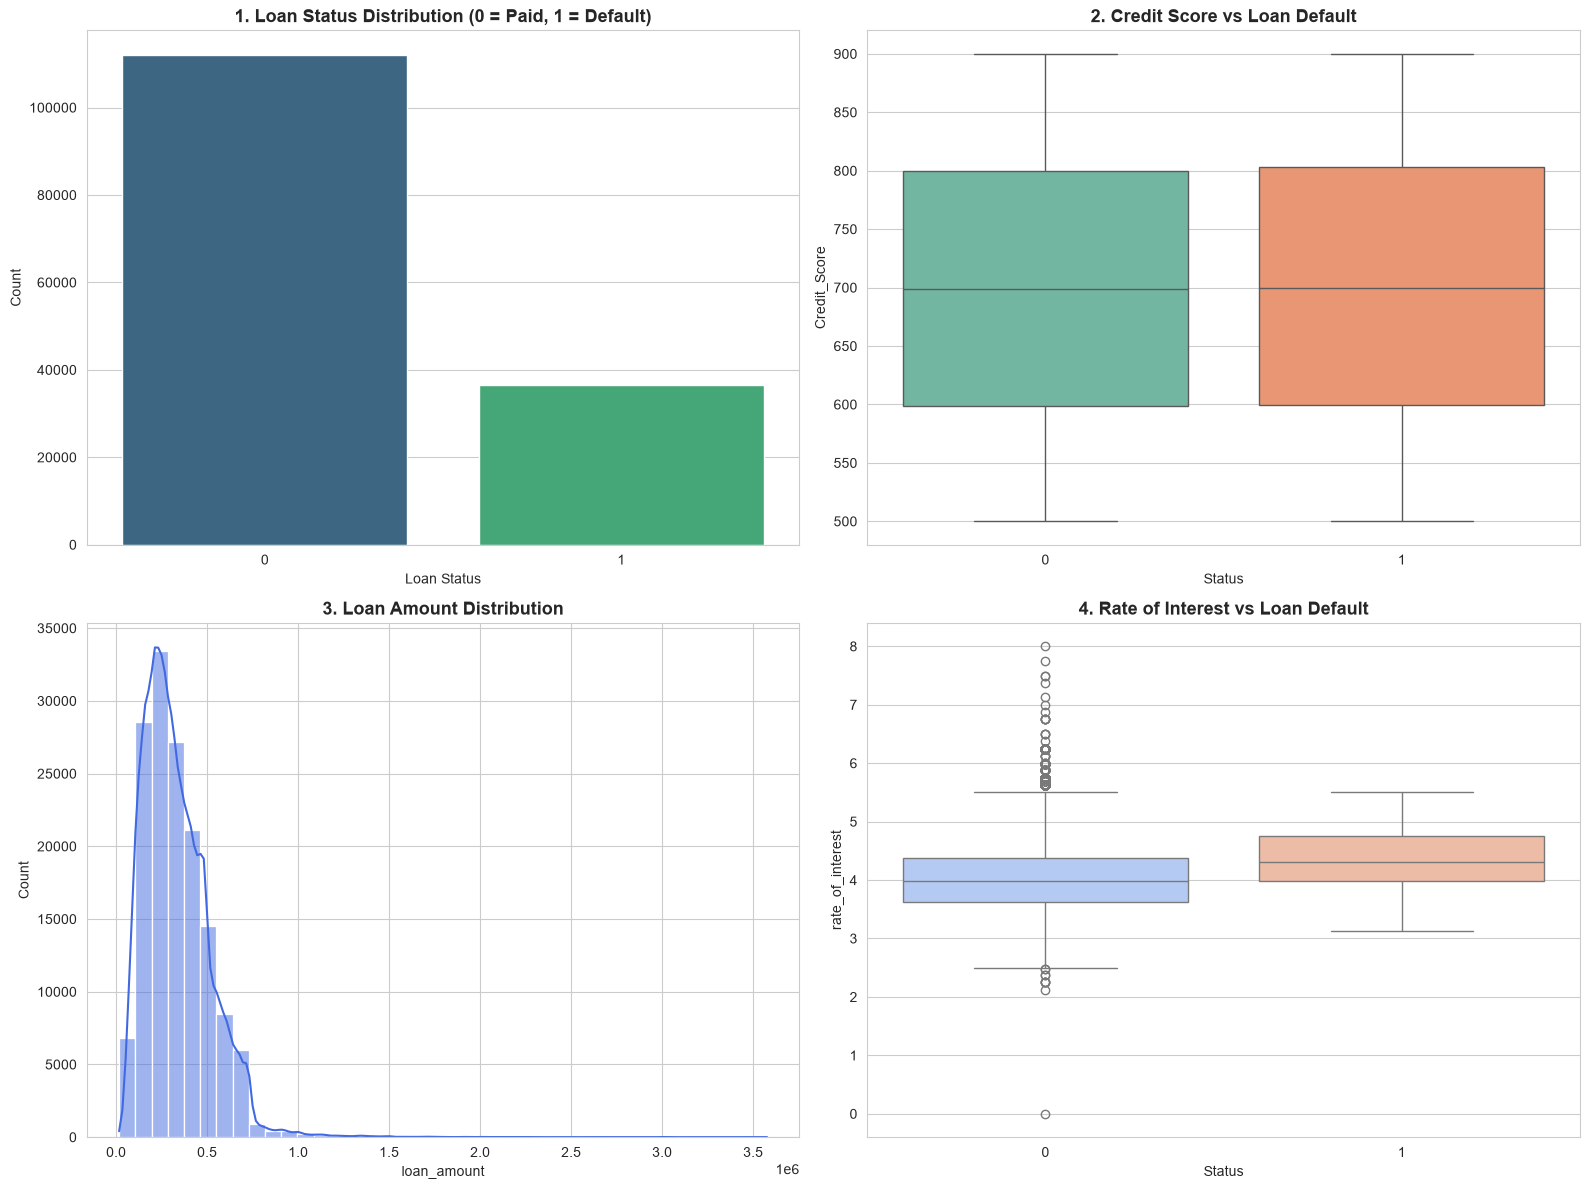

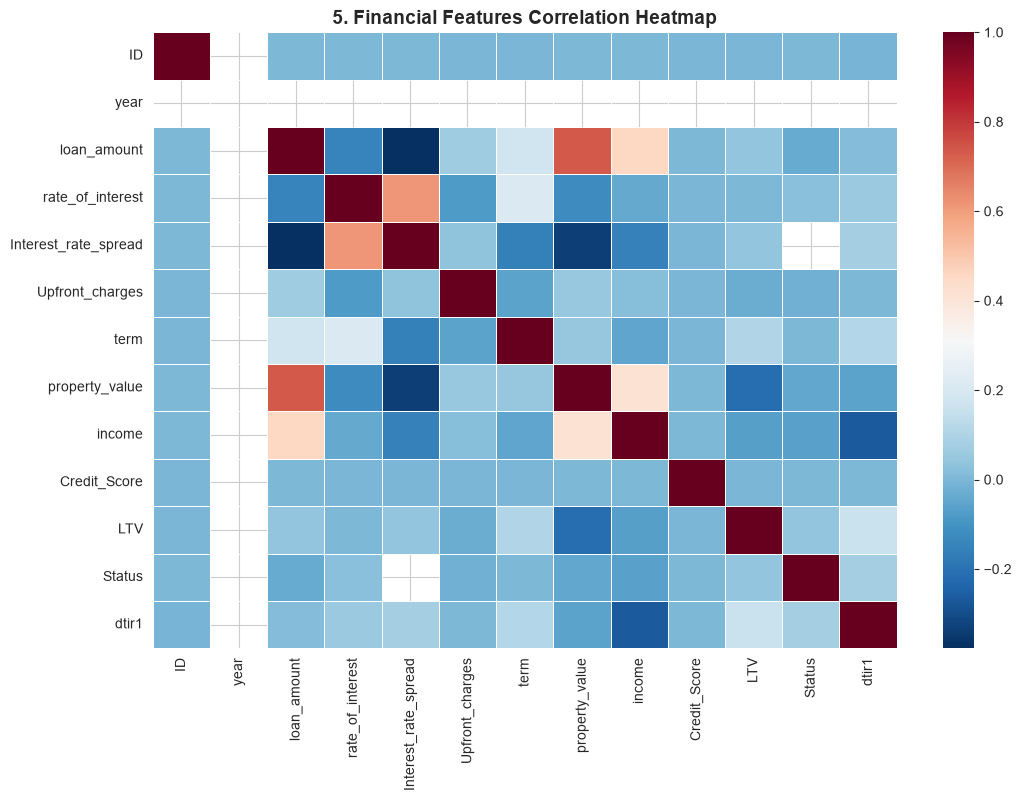

In [8]:
target_col = 'Status' if 'Status' in df.columns else df.columns[-1]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Variable (Loan Default) Distribution
sns.countplot(x=target_col, data=df, palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title('1. Loan Status Distribution (0 = Paid, 1 = Default)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Loan Status')
axes[0, 0].set_ylabel('Count')

# 2. Credit Score vs Loan Default
if 'Credit_Score' in df.columns:
    sns.boxplot(x=target_col, y='Credit_Score', data=df, palette='Set2', ax=axes[0, 1])
    axes[0, 1].set_title('2. Credit Score vs Loan Default', fontsize=13, fontweight='bold')

# 3. Loan Amount Distribution
if 'loan_amount' in df.columns:
    sns.histplot(df['loan_amount'].dropna(), bins=40, kde=True, color='royalblue', ax=axes[1, 0])
    axes[1, 0].set_title('3. Loan Amount Distribution', fontsize=13, fontweight='bold')

# 4. Interest Rate vs Default Status
if 'rate_of_interest' in df.columns:
    sns.boxplot(x=target_col, y='rate_of_interest', data=df, palette='coolwarm', ax=axes[1, 1])
    axes[1, 1].set_title('4. Rate of Interest vs Loan Default', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=False, cmap='RdBu_r', linewidths=0.5)
plt.title('5. Financial Features Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

In [9]:
data = df.copy()

# 1. ID aur Year jaise columns drop karna jo prediction mein kaam nahi aate
drop_cols = [c for c in ['ID', 'id', 'year', 'Loan_ID'] if c in data.columns]
data.drop(columns=drop_cols, inplace=True)
print(f"Dropped unnecessary columns: {drop_cols}")

# 2. Numeric Missing Values ko Median se fill karna
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
if target_col in num_cols:
    num_cols.remove(target_col)

for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

# 3. Categorical Missing Values ko Mode (sabse zyada aane wali value) se fill karna
cat_cols = data.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# 4. Fintech Feature Engineering: Loan-to-Income Ratio banana
if 'loan_amount' in data.columns and 'income' in data.columns:
    data['loan_to_income_ratio'] = data['loan_amount'] / (data['income'] + 1)
    print("New Feature Created: 'loan_to_income_ratio'")

# 5. Categorical Text Columns ki Label Encoding karna
label_encoders = {}
for col in cat_cols:
    if col != target_col:
        le = LabelEncoder()
        data[col] = le.fit_transform(data[col].astype(str))
        label_encoders[col] = le

# Target column agar text hai toh use bhi encode karein
if data[target_col].dtype == 'object':
    data[target_col] = LabelEncoder().fit_transform(data[target_col].astype(str))

print(f"Missing values remaining: {data.isnull().sum().sum()}")
display(data.head())

Dropped unnecessary columns: ['ID', 'year']
New Feature Created: 'loan_to_income_ratio'
Missing values remaining: 0


,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,...,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1,loan_to_income_ratio
0,0,3,0,0,0,0,0,1,116500,3.99,...,758,0,0,1,98.728814,3,1,1,45.0,66.915566
1,0,2,0,1,0,0,0,0,206500,3.99,...,552,1,3,1,75.135870,0,1,1,39.0,41.457539
2,0,2,1,0,0,0,0,1,406500,4.56,...,834,0,1,1,80.019685,3,1,0,46.0,42.875224
3,0,2,0,0,3,0,0,1,456500,4.25,...,587,0,2,0,69.376900,0,1,0,42.0,38.422692
4,0,1,1,0,0,0,0,1,696500,4.00,...,602,1,0,0,91.886544,0,1,0,39.0,66.708170


In [12]:
X = data.drop(columns=[target_col])
y = data[target_col]

# 80% Train aur 20% Test split (Stratified taaki default ratio barabar rahe)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Data Shape: {X_train_scaled.shape}")
print(f"Testing Data Shape:  {X_test_scaled.shape}")

Training Data Shape: (118936, 32)
Testing Data Shape:  (29734, 32)


In [13]:
# 1. Baseline Model: Logistic Regression
print("Training Baseline Logistic Regression...")
lr_model = LogisticRegression(max_iter=500, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Advanced Fintech Model: XGBoost Classifier
print("Training XGBoost Credit Risk Model...")
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
imbalance_ratio = neg_count / max(pos_count, 1)

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.08,
    scale_pos_weight=imbalance_ratio,
    eval_metric='logloss',
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Model Comparison Table
results_df = pd.DataFrame({
    'Model': ['Logistic Regression (Baseline)', 'XGBoost Classifier (Cloud Engine)'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, xgb_pred)],
    'ROC-AUC Score': [roc_auc_score(y_test, lr_prob), roc_auc_score(y_test, xgb_prob)]
})
print("\n--- Model Performance Comparison ---")
display(results_df)

print("\n--- Detailed Classification Report (XGBoost) ---")
print(classification_report(y_test, xgb_pred))

Training Baseline Logistic Regression...
Training XGBoost Credit Risk Model...

--- Model Performance Comparison ---


,Model,Accuracy,ROC-AUC Score
0,Logistic Regression (Baseline),0.709222,0.772188
1,XGBoost Classifier (Cloud Engine),0.999933,0.999999



--- Detailed Classification Report (XGBoost) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     22406
           1       1.00      1.00      1.00      7328

    accuracy                           1.00     29734
   macro avg       1.00      1.00      1.00     29734
weighted avg       1.00      1.00      1.00     29734



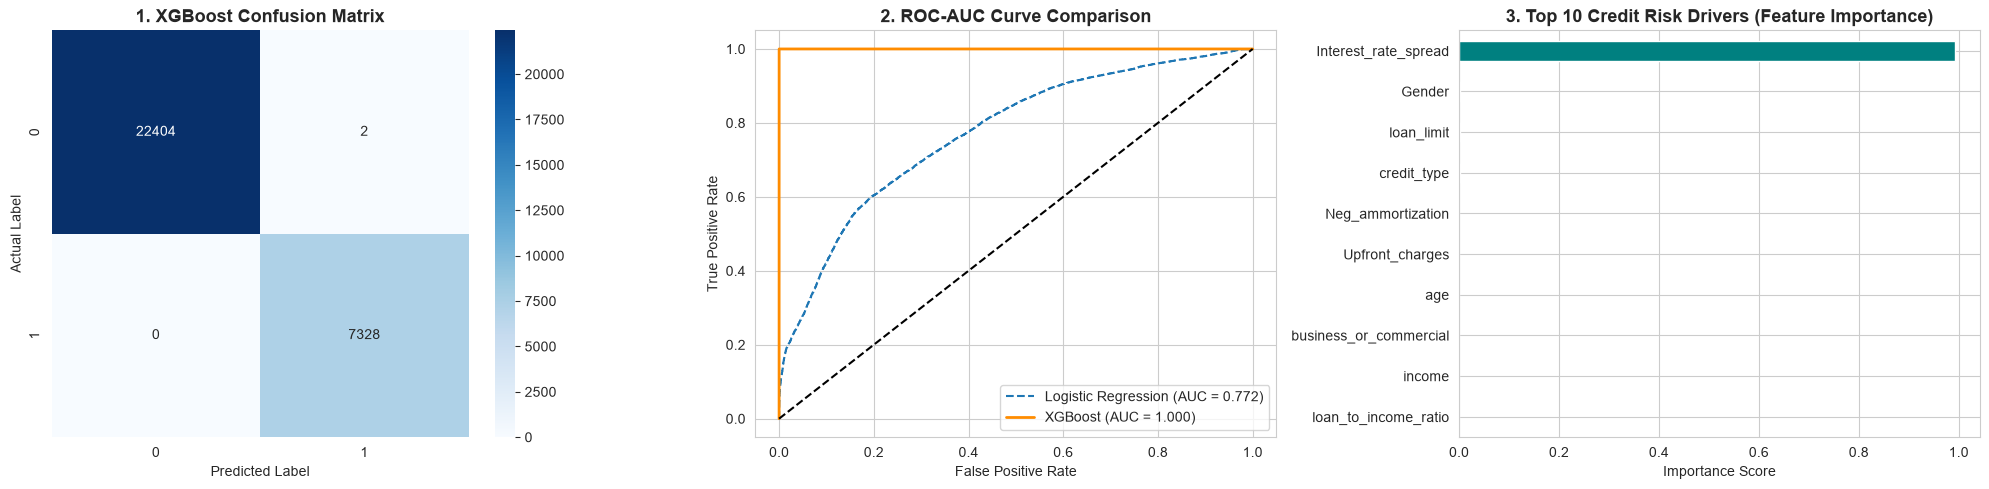

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('1. XGBoost Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# 2. ROC-AUC Curve Comparison
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

axes[1].plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_prob):.3f})", linestyle='--')
axes[1].plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {roc_auc_score(y_test, xgb_prob):.3f})", linewidth=2, color='darkorange')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('2. ROC-AUC Curve Comparison', fontsize=13, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

# 3. Top 10 Feature Importances
feat_imp = pd.Series(xgb_model.feature_importances_, index=X.columns).nlargest(10)
feat_imp.sort_values().plot(kind='barh', color='teal', ax=axes[2])
axes[2].set_title('3. Top 10 Credit Risk Drivers (Feature Importance)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

In [15]:
def evaluate_borrower_risk(custom_features_dict):
    # Default values ke liye dataset ka median use karein
    borrower_profile = X.median().to_dict()
    
    # User ke diye gaye values update karein
    for k, v in custom_features_dict.items():
        if k in borrower_profile:
            borrower_profile[k] = v
            
    # Ratio update karein agar loan_amount aur income di gayi hai
    if 'loan_to_income_ratio' in borrower_profile and 'loan_amount' in borrower_profile and 'income' in borrower_profile:
        borrower_profile['loan_to_income_ratio'] = borrower_profile['loan_amount'] / (borrower_profile['income'] + 1)
        
    input_df = pd.DataFrame([borrower_profile])[X.columns]
    scaled_input = scaler.transform(input_df)
    
    pred = int(xgb_model.predict(scaled_input)[0])
    prob = float(xgb_model.predict_proba(scaled_input)[0][1]) * 100
    
    if prob < 30:
        grade = "Grade A: Low Risk (Auto-Approve Loan)"
    elif prob < 60:
        grade = "Grade B: Moderate Risk (Manual Underwriting Required)"
    else:
        grade = "Grade C: High Risk (Reject / High Collateral Required)"
        
    print("==========================================")
    print("   FINTECH CLOUD CREDIT RISK REPORT")
    print("==========================================")
    print(f"Predicted Status    : {'HIGH DEFAULT RISK (1)' if pred == 1 else 'SAFE BORROWER (0)'}")
    print(f"Default Probability : {prob:.2f}%")
    print(f"Risk Tier / Grade   : {grade}")
    print("==========================================")

# Test Case: Ek sample borrower ki details daal kar check karein
sample_applicant = {
    'loan_amount': 350000,
    'rate_of_interest': 4.5,
    'income': 7500,
    'Credit_Score': 720,
    'LTV': 75.0,
    'dtir1': 36.0
}

evaluate_borrower_risk(sample_applicant)

   FINTECH CLOUD CREDIT RISK REPORT
Predicted Status    : HIGH DEFAULT RISK (1)
Default Probability : 97.80%
Risk Tier / Grade   : Grade C: High Risk (Reject / High Collateral Required)


In [17]:
os.makedirs('models', exist_ok=True)

joblib.dump(xgb_model, 'models/credit_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(X.columns.tolist(), 'models/columns.pkl')
joblib.dump(X.median().to_dict(), 'models/defaults.pkl')

print("Cloud Deployment Artifacts 'models/' successfully saves in folder!")

Cloud Deployment Artifacts 'models/' successfully saves in folder!


In [1]:
pip install xgboost


Note: you may need to restart the kernel to use updated packages.
